**quantum_runs** - executed copy of `QML.ipynb` (run `qml_ibm_156q`).

Parameter overrides: `IMAGE_ROWS=12 IMAGE_COLS=13 TRAIN_IMAGES=2 TEST_IMAGES=2 OPTIMIZER="Powell" MAX_ITERATIONS=3 TARGET="ibm"`

The next cell routes `cudaq.sample` / `cudaq.observe` to IBM Quantum hardware (see `quantum_runs/ibm_shim.py`). The notebook's own code is unchanged.

In [1]:
import sys; sys.path.insert(0, '/home/user/silver-train/quantum_runs')
import ibm_shim; ibm_shim.install()

[ibm] IBM routing installed (mode=ibm, run=qml_ibm_156q)


/home/user/silver-train/quantum_runs/ibm_shim.py:38: FutureWarning: The CUDA-Q `sample` and `observe` algorithmic primitives will change in a future release. Existing code may require updates. See https://nvidia.github.io/cuda-quantum/latest/using/migration/upcoming_changes.html for details.
  import cudaq


# QML - Quantum Convolutional Neural Network (QCNN)
### Classifying images with a quantum convolutional neural network in NVIDIA CUDA-Q
*Notebook 6 of 8 - CUDA-Q Quantum Algorithm Benchmarking Suite*

This notebook trains a **Quantum Convolutional Neural Network (QCNN)** to tell images of **horizontal** lines from
images of **vertical** lines. Every pixel is one qubit. The default is 2 x 4 pixels = 8 qubits so that training
finishes in seconds on any laptop; 3 x 5 pixels = 15 qubits is a one-line change (recommended on a GPU, see Section 3).

This notebook is intentionally **short and easy to modify**: all settings are in Section 3, the whole quantum circuit
is one small kernel (Section 5), and the training loop is plain Python (Section 7).

| Section | Content |
|---|---|
| 1 | Problem statement and mathematics |
| 2 | Import libraries |
| 3 | Input parameters - **edit only this cell** |
| 4 | Example input: the image dataset |
| 5 | Quantum circuit: the QCNN kernel and its drawing |
| 6 | Expected output (before training) |
| 7 | Training (execution cell) |
| 8 | Results and visualization |
| 9 | Final report |

---
## Section 1 - Problem statement and mathematical explanation

### What problem does the algorithm solve?
**Supervised classification:** given labelled examples $(x_m, y_m)$ - here small grey-scale images $x$ with label
$y = +1$ (horizontal line) or $y = -1$ (vertical line) - learn a model that predicts the label of *new* images.

### Why is this problem important?
Classification is the core task of machine learning. The QCNN (Cong, Choi & Lukin, *Nature Physics* 2019) is a
quantum neural network with the structure of a classical CNN: local "filters" with **shared weights** and
**pooling** layers that halve the number of active qubits. It needs only $O(\log N)$ parameters for $N$ qubits,
its training landscape provably avoids barren plateaus (Pesah et al., 2021), and it is used both for classical data
and for recognising quantum phases of matter.

### What is the classical approach?
A classical convolutional neural network, or even logistic regression on the pixels, solves this toy task easily.
The goal here is to show how a QCNN works and how it is trained - not to beat classical methods.

### How does the quantum algorithm solve it?
1. **Encoding.** Pixel $x_i \in [0, 1]$ is written into qubit $i$ with a rotation:
   $|\psi(x)\rangle = \bigotimes_i R_Y(\pi x_i)|0\rangle = \bigotimes_i\big(\cos\tfrac{\pi x_i}{2}|0\rangle + \sin\tfrac{\pi x_i}{2}|1\rangle\big)$.
   A lit pixel ($x_i = 1$) becomes $|1\rangle$, a dark one stays close to $|0\rangle$.
2. **Convolution layer** $\ell$: the *same* two-qubit block is applied to every pair of neighbouring active qubits
   (first pairs (0,1), (2,3), ..., then (1,2), (3,4), ...):
   $U_\ell = \mathrm{CNOT}\,\big(R_Y(\theta_{\ell,1}) \otimes R_Y(\theta_{\ell,2})\big)$ - like a CNN filter with shared weights.
3. **Pooling layer** $\ell$: for each pair (source $s$, sink $k$) the sink is rotated depending on the source,
   $P_\ell = |0\rangle\langle 0|_s \otimes R_X(\theta_{\ell,4}) + |1\rangle\langle 1|_s \otimes R_Z(\theta_{\ell,3})$,
   and the source is **discarded** (never used again). This equals "measure the source and rotate the sink according to
   the result" (deferred-measurement principle), so no mid-circuit measurement is needed. The number of active qubits halves.
4. Repeat until **one qubit** is left: $\lceil \log_2 N\rceil$ layers with 4 parameters each
   (8 qubits $\to$ 4 $\to$ 2 $\to$ 1: 3 layers, 12 parameters; 15 qubits $\to$ 8 $\to$ 4 $\to$ 2 $\to$ 1: 4 layers, 16 parameters).
5. **Readout** of the last qubit: $f(x;\boldsymbol\theta) = \langle Z_{\text{out}}\rangle \in [-1, 1]$, prediction
   $\hat y = \operatorname{sign} f(x;\boldsymbol\theta)$.
6. **Training** minimises the mean squared error with a classical optimizer (COBYLA):
   $\displaystyle \mathcal L(\boldsymbol\theta) = \frac{1}{M}\sum_{m=1}^{M}\big(f(x_m;\boldsymbol\theta) - y_m\big)^2 .$

### Measurement
On a simulator `cudaq.observe` returns $\langle Z_{\text{out}}\rangle$ exactly. On real hardware it is estimated from
shots: $\langle Z\rangle = P(0) - P(1)$ for the output qubit.

### What is the expected solution?
Random guessing gives 50 % accuracy. After training, the QCNN should classify most training and test images correctly
(loss well below its starting value). The exact numbers depend on the random images, the initial parameters and the
optimizer budget - they are measured, not assumed.

---
## Section 2 - Import libraries

Install once (Python >= 3.11): `pip install cudaq numpy scipy matplotlib` - see the repository README for GPU setup.

In [2]:
import os                                     # folder for the saved circuit drawing
import time                                   # wall-clock timing
import warnings                               # hide two harmless CUDA-Q notices printed at import
warnings.filterwarnings("ignore", message=".*cudaq-logical is in preview.*")
warnings.filterwarnings("ignore", message=".*algorithmic primitives will change.*")

import numpy as np                            # arrays and random numbers
import matplotlib.pyplot as plt               # plots
from scipy.optimize import minimize           # classical optimizer for the QCNN parameters
import cudaq                                  # NVIDIA CUDA-Q

print("CUDA-Q :", cudaq.__version__.split("(")[0].replace("CUDA-Q Version", "").strip())
print("NumPy  :", np.__version__)
print("GPUs visible to CUDA-Q:", cudaq.num_available_gpus())

# colours used in the plots (colour-blind-safe palette, same as the other notebooks)
BLUE, ORANGE, GREY, GOOD, BAD = "#2a78d6", "#eb6834", "#898781", "#0ca30c", "#d03b3b"
plt.rcParams.update({"axes.grid": True, "grid.color": "#e1e0d9", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.axisbelow": True})

CUDA-Q : 0.16.0
NumPy  : 2.5.4
GPUs visible to CUDA-Q: 0


---
## Section 3 - Input parameters

Edit only this cell. The number of qubits is the number of pixels: `N = IMAGE_ROWS * IMAGE_COLS`.

| Parameter | Meaning | What happens if you change it |
|---|---|---|
| `IMAGE_ROWS`, `IMAGE_COLS` | Image size; one qubit per pixel. | 2 x 4 = 8 qubits (default: training runs the circuit about 2,000 times, which takes seconds at 8 qubits on a CPU), 3 x 5 = 15, 4 x 4 = 16, 4 x 5 = 20, 5 x 6 = 30. Every extra qubit doubles the simulation cost: 15 qubits took ~0.35 s per circuit on a 4-core CPU (~10+ minutes of training), so use `TARGET = "nvidia"` (GPU) for 15+ qubits and raise `MAX_ITERATIONS` (deeper QCNNs need more optimizer steps). |
| `LINE_LENGTH` | Number of lit pixels in a line. | Must fit in both directions (<= rows and <= columns). |
| `NOISE_LEVEL` | Brightness of random background pixels (0 ... 1). | More noise = harder task. |
| `TRAIN_IMAGES`, `TEST_IMAGES` | Dataset sizes (half horizontal, half vertical). | Training time grows linearly with `TRAIN_IMAGES`. |
| `OPTIMIZER`, `MAX_ITERATIONS` | SciPy optimizer and its budget of loss evaluations. | Each evaluation runs the circuit once per training image. Too few iterations stop before the model has learned. |
| `INITIAL_PARAMETER_SCALE` | Initial parameters are drawn uniformly from [0, scale]. | Different starting points can lead to different final accuracies. |
| `TARGET` | CUDA-Q target. `"auto"` = `"nvidia"` (GPU) if available, else `"qpp-cpu"`. | Any CUDA-Q simulator name works, e.g. `"nvidia"`, `"qpp-cpu"`, `"tensornet-mps"` (GPU). |
| `SEED` | Random seed. | Same seed = same images, same initial parameters, same result. |
| `SAVE_CIRCUIT_DRAWING` | Save the circuit drawing to `exports/qml/qcnn_circuit.txt`. | `False` writes nothing. |

In [3]:
# =====================================================================================
# Section 3 - INPUT PARAMETERS  (edit only this cell)
# =====================================================================================
IMAGE_ROWS = 12                  # image height in pixels
IMAGE_COLS = 13                  # image width in pixels  ->  N_QUBITS = 2 * 4 = 8  (3 x 5 = 15 qubits: use a GPU)
LINE_LENGTH = 2                 # lit pixels per line (must be <= IMAGE_ROWS and <= IMAGE_COLS)
NOISE_LEVEL = 0.25              # background pixels are random numbers in [0, NOISE_LEVEL]
TRAIN_IMAGES = 2               # training images (half horizontal, half vertical)
TEST_IMAGES = 2                # test images, never seen during training

OPTIMIZER = "Powell"            # "COBYLA" (recommended), "Nelder-Mead" or "Powell"
MAX_ITERATIONS = 3            # maximum number of loss evaluations
INITIAL_PARAMETER_SCALE = 3.14  # initial parameters uniform in [0, scale]

TARGET = "ibm"                 # "auto", "qpp-cpu", "nvidia", "tensornet-mps", ...
SEED = 42                       # reproducibility
SAVE_CIRCUIT_DRAWING = True     # write the circuit drawing to exports/qml/qcnn_circuit.txt

N_QUBITS = IMAGE_ROWS * IMAGE_COLS   # one qubit per pixel (computed, do not edit)

---
## Section 4 - Example input: the image dataset

Each image has a dark, slightly noisy background and **one line** of `LINE_LENGTH` lit pixels, either horizontal
(label $+1$) or vertical (label $-1$), at a random position. The images are flattened row by row, so pixel
(row $r$, column $c$) is written into qubit $r \cdot$ `IMAGE_COLS` $+ c$.

To use **your own data**, replace `make_images` by any function that returns an array of shape
`(number_of_images, N_QUBITS)` with values in [0, 1] and labels in {+1, -1}.

156 pixels = 156 qubits;  2 training images, 2 test images


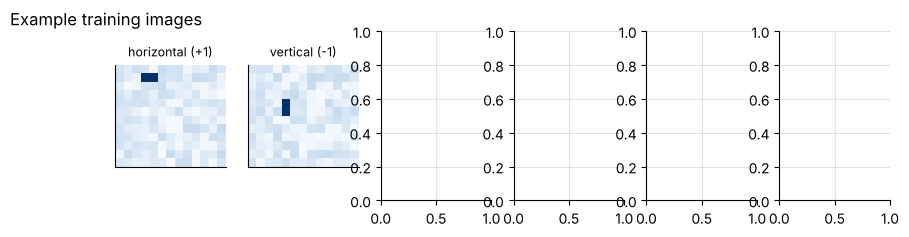

In [4]:
if LINE_LENGTH > min(IMAGE_ROWS, IMAGE_COLS):
    raise ValueError("LINE_LENGTH must fit both horizontally and vertically (<= IMAGE_ROWS and <= IMAGE_COLS).")
if N_QUBITS < 4:
    raise ValueError("Use at least 4 pixels (e.g. 2 x 2).")

rng = np.random.default_rng(SEED)              # one random generator for everything -> reproducible

def make_images(count):
    """Return (images, labels): images has shape (count, N_QUBITS); labels are +1 (horizontal) / -1 (vertical)."""
    images, labels = [], []
    for k in range(count):
        image = rng.uniform(0, NOISE_LEVEL, size=(IMAGE_ROWS, IMAGE_COLS))   # noisy dark background
        if k % 2 == 0:                                                        # horizontal line
            row = rng.integers(IMAGE_ROWS)
            col = rng.integers(IMAGE_COLS - LINE_LENGTH + 1)
            image[row, col:col + LINE_LENGTH] = 1.0
            labels.append(+1)
        else:                                                                 # vertical line
            col = rng.integers(IMAGE_COLS)
            row = rng.integers(IMAGE_ROWS - LINE_LENGTH + 1)
            image[row:row + LINE_LENGTH, col] = 1.0
            labels.append(-1)
        images.append(image.ravel())                                          # flatten row by row: pixel -> qubit
    return np.array(images), np.array(labels)

train_x, train_y = make_images(TRAIN_IMAGES)
test_x, test_y = make_images(TEST_IMAGES)
print(f"{N_QUBITS} pixels = {N_QUBITS} qubits;  {TRAIN_IMAGES} training images, {TEST_IMAGES} test images")

fig, axes = plt.subplots(1, 6, figsize=(10, 2.2))
for ax, image, label in zip(axes, train_x, train_y):
    ax.imshow(image.reshape(IMAGE_ROWS, IMAGE_COLS), cmap="Blues", vmin=0, vmax=1)
    ax.set_title("horizontal (+1)" if label > 0 else "vertical (-1)", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.suptitle("Example training images", x=0.02, ha="left")
plt.show()

---
## Section 5 - Quantum circuit

**Backend.** CUDA-Q runs the same kernel on a CPU simulator, a GPU simulator or a QPU; only `cudaq.set_target` changes.

**Layout.** `qcnn_layout(n)` decides, in plain Python, which qubit pairs each layer acts on. It returns one list of
operations; each entry says *what* to do (0 = convolution block, 1 = pooling block), on *which two qubits* and with
*which layer's parameters*. The kernel `qcnn` simply walks through that list - to change the architecture you only edit
`qcnn_layout` or the two blocks inside the kernel.

In [5]:
# ---- choose the simulator --------------------------------------------------------------
target_name = ("nvidia" if cudaq.num_available_gpus() > 0 else "qpp-cpu") if TARGET == "auto" else TARGET
if target_name in ("nvidia", "nvidia-fp64", "tensornet", "tensornet-mps") and cudaq.num_available_gpus() == 0:
    raise ValueError(f"TARGET '{target_name}' needs an NVIDIA GPU, but none is visible. Use 'qpp-cpu'.")
cudaq.set_target(target_name)                  # CPU or GPU simulator
cudaq.set_random_seed(SEED)                    # reproducible sampling
print("CUDA-Q target:", cudaq.get_target().name)


def qcnn_layout(n):
    """Operation list of a QCNN on n qubits: (kind, qubit_a, qubit_b, layer) with kind 0 = conv, 1 = pool."""
    kinds, qubit_a, qubit_b, layers = [], [], [], []
    active, layer = list(range(n)), 0                    # qubits still in use, current layer
    while len(active) > 1:
        for start in (0, 1):                             # convolution: pairs (0,1),(2,3),... then (1,2),(3,4),...
            for i in range(start, len(active) - 1, 2):
                kinds.append(0); qubit_a.append(active[i]); qubit_b.append(active[i + 1]); layers.append(layer)
        kept = []
        for i in range(0, len(active) - 1, 2):           # pooling: active[i] (source) -> active[i+1] (sink)
            kinds.append(1); qubit_a.append(active[i]); qubit_b.append(active[i + 1]); layers.append(layer)
            kept.append(active[i + 1])                   # the sink survives, the source is discarded
        if len(active) % 2 == 1:
            kept.append(active[-1])                      # odd number of qubits: the last one moves on unchanged
        active, layer = kept, layer + 1
    return kinds, qubit_a, qubit_b, layers, active[0], layer   # ..., output qubit, number of layers


@cudaq.kernel
def qcnn(pixels: list[float], theta: list[float], kinds: list[int], qubit_a: list[int],
         qubit_b: list[int], layers: list[int]):
    qubits = cudaq.qvector(len(pixels))                  # one qubit per pixel, all start in |0>
    for i in range(len(pixels)):
        ry(np.pi * pixels[i], qubits[i])                 # encode pixel value as a rotation angle
    for k in range(len(kinds)):
        t = 4 * layers[k]                                # this layer's 4 parameters: theta[t ... t+3]
        a = qubit_a[k]
        b = qubit_b[k]
        if kinds[k] == 0:                                # ---- convolution block (shared weights) ----
            ry(theta[t], qubits[a])
            ry(theta[t + 1], qubits[b])
            x.ctrl(qubits[a], qubits[b])
        else:                                            # ---- pooling block: a -> b, then a is discarded ----
            rz.ctrl(theta[t + 2], qubits[a], qubits[b])  # if a = 1: rotate b around Z
            x(qubits[a])
            rx.ctrl(theta[t + 3], qubits[a], qubits[b])  # if a = 0: rotate b around X
            x(qubits[a])


kinds, qubit_a, qubit_b, layers, output_qubit, n_layers = qcnn_layout(N_QUBITS)
n_parameters = 4 * n_layers
readout = cudaq.spin.z(output_qubit)                     # measure <Z> on the last remaining qubit
print(f"QCNN on {N_QUBITS} qubits: {n_layers} layers, {len(kinds)} blocks, {n_parameters} trainable parameters, "
      f"output qubit {output_qubit}")

CUDA-Q target: ibm
QCNN on 156 qubits: 8 layers, 460 blocks, 32 trainable parameters, output qubit 155


In [6]:
# ---- circuit drawing (at most 10 qubits) ------------------------------------------------
n_draw = min(N_QUBITS, 10)
draw_layout = qcnn_layout(n_draw)
drawing = cudaq.draw(qcnn, [0.5] * n_draw, [0.1] * (4 * draw_layout[5]), *draw_layout[:4])
if n_draw < N_QUBITS:
    print(f"CIRCUIT VISUALIZATION EXAMPLE: {n_draw}-qubit QCNN - NOT the full {N_QUBITS}-qubit circuit that is trained.")
print(drawing)
if SAVE_CIRCUIT_DRAWING:
    os.makedirs("exports/qml", exist_ok=True)
    with open("exports/qml/qcnn_circuit.txt", "w", encoding="utf-8") as fh:
        fh.write(drawing)
    print("Saved to exports/qml/qcnn_circuit.txt")
resources = cudaq.estimate_resources(qcnn, list(train_x[0]), [0.1] * n_parameters, kinds, qubit_a, qubit_b, layers)
print(f"Full {N_QUBITS}-qubit circuit: {resources.count()} gates, depth {resources.depth}, gate counts {resources.to_dict()}")

CIRCUIT VISUALIZATION EXAMPLE: 10-qubit QCNN - NOT the full 156-qubit circuit that is trained.
     ╭───────────╮╭─────────╮                                ╭───╮           »
q0 : ┤ ry(1.571) ├┤ ry(0.1) ├──●───────────────────────●─────┤ x ├─────●─────»
     ├───────────┤├─────────┤╭─┴─╮╭─────────╮     ╭────┴────╮╰───╯╭────┴────╮»
q1 : ┤ ry(1.571) ├┤ ry(0.1) ├┤ x ├┤ ry(0.1) ├──●──┤ rz(0.1) ├─────┤ rx(0.1) ├»
     ├───────────┤├─────────┤╰───╯├─────────┤╭─┴─╮╰─────────╯╭───╮╰─────────╯»
q2 : ┤ ry(1.571) ├┤ ry(0.1) ├──●──┤ ry(0.1) ├┤ x ├─────●─────┤ x ├─────●─────»
     ├───────────┤├─────────┤╭─┴─╮├─────────┤╰───╯╭────┴────╮╰───╯╭────┴────╮»
q3 : ┤ ry(1.571) ├┤ ry(0.1) ├┤ x ├┤ ry(0.1) ├──●──┤ rz(0.1) ├─────┤ rx(0.1) ├»
     ├───────────┤├─────────┤╰───╯├─────────┤╭─┴─╮╰─────────╯╭───╮╰─────────╯»
q4 : ┤ ry(1.571) ├┤ ry(0.1) ├──●──┤ ry(0.1) ├┤ x ├─────●─────┤ x ├─────●─────»
     ├───────────┤├─────────┤╭─┴─╮├─────────┤╰───╯╭────┴────╮╰───╯╭────┴────╮»
q5 : ┤ ry(1.571) ├┤ ry(0.1) ├┤ x ├┤ 

Full 156-qubit circuit: 1691 gates, depth 56, gate counts {'ry': 766, 'cx': 305, 'crz': 155, 'x': 310, 'crx': 155}


---
## Section 6 - Expected output (before training)

* **Training curves:** the loss should fall from its starting value (around 1 for random parameters) and the training
  accuracy should rise from about 50 % (random guessing). Curves may be flat at first while the optimizer explores.
* **Test accuracy** on images the QCNN has never seen - this shows whether it learned the concept "horizontal vs vertical".
* **Prediction gallery:** test images with their predicted labels (green = correct, red = wrong) and a histogram of the
  QCNN output $\langle Z\rangle$ for both classes (well separated = confident classifier).
* **Cost:** one loss evaluation runs the circuit once per training image. The next cell times one circuit and
  estimates the training time (an estimate: optimizer overhead is small, but CPUs vary). State memory: 16 x 2^N bytes.

In [7]:
theta_initial = rng.uniform(0, INITIAL_PARAMETER_SCALE, n_parameters)   # random starting parameters
cudaq.observe(qcnn, readout, list(train_x[0]), list(theta_initial), kinds, qubit_a, qubit_b, layers)  # warm-up (JIT)
start = time.perf_counter()
for image in train_x[:3]:
    cudaq.observe(qcnn, readout, list(image), list(theta_initial), kinds, qubit_a, qubit_b, layers)
seconds_per_circuit = (time.perf_counter() - start) / 3
circuits = TRAIN_IMAGES * MAX_ITERATIONS + TEST_IMAGES
print(f"Time per circuit          : {seconds_per_circuit * 1e3:.1f} ms on {cudaq.get_target().name}")
print(f"Circuits to run           : {TRAIN_IMAGES} images x {MAX_ITERATIONS} iterations + {TEST_IMAGES} test = {circuits}")
print(f"Estimated training time   : about {circuits * seconds_per_circuit / 60:.1f} min")
state_bytes = 16 * 2 ** N_QUBITS                                          # complex128 amplitudes
print(f"State-vector memory       : {state_bytes / 1e3:,.1f} KB (16 bytes x 2^{N_QUBITS})")

[ibm] account S.No 25: using backend ibm_kingston (queue 27)


[ibm] submitted job dbnlmhlt7fqc73ajrg40 (1 circuit(s), 1000 shots, 156-qubit chip ibm_kingston, account S.No 25)


[ibm] submitted job dbnlo3k4148s73918a9g (1 circuit(s), 1000 shots, 156-qubit chip ibm_kingston, account S.No 25)


---
## Section 7 - Training (execution cell)

`predict` runs the QCNN on a list of images and returns $\langle Z_{\text{out}}\rangle$ for each. `loss` is the mean
squared error on the training set; every call is recorded so we can plot the training curves.

In [7]:
# =====================================================================================
# >>> EXECUTION CELL - train the QCNN <<<
# =====================================================================================
def predict(theta, images):
    """QCNN outputs <Z_out> in [-1, 1] for every image (positive -> horizontal, negative -> vertical)."""
    return np.array([cudaq.observe(qcnn, readout, list(image), list(theta), kinds, qubit_a, qubit_b, layers).expectation()
                     for image in images])

history = {"loss": [], "accuracy": []}

def loss(theta):
    outputs = predict(theta, train_x)
    history["loss"].append(np.mean((outputs - train_y) ** 2))           # mean squared error
    history["accuracy"].append(np.mean(np.sign(outputs) == train_y))    # fraction of correct training predictions
    if len(history["loss"]) % 10 == 0:
        print(f"  evaluation {len(history['loss']):4d}: loss {history['loss'][-1]:.4f}, "
              f"training accuracy {history['accuracy'][-1]:.2f}")
    return history["loss"][-1]

budget = {"COBYLA": {"maxiter": MAX_ITERATIONS}, "Nelder-Mead": {"maxfev": MAX_ITERATIONS},
          "Powell": {"maxfev": MAX_ITERATIONS}}[OPTIMIZER]
start = time.perf_counter()
result = minimize(loss, theta_initial, method=OPTIMIZER, options=budget)   # classical optimisation loop
training_time = time.perf_counter() - start

theta_trained = result.x
start = time.perf_counter()
test_outputs = predict(theta_trained, test_x)
test_time = time.perf_counter() - start
train_outputs = predict(theta_trained, train_x)
train_accuracy = np.mean(np.sign(train_outputs) == train_y)
test_accuracy = np.mean(np.sign(test_outputs) == test_y)
print(f"\nTraining finished: {len(history['loss'])} evaluations in {training_time:.1f} s ({OPTIMIZER})")
final_loss = np.mean((train_outputs - train_y) ** 2)                   # loss of the trained parameters
print(f"Final loss        : {final_loss:.4f}")
print(f"Training accuracy : {train_accuracy:.2%}")
print(f"Test accuracy     : {test_accuracy:.2%}   (random guessing: 50%)")

  evaluation   10: loss 1.0272, training accuracy 0.40


  evaluation   20: loss 0.9286, training accuracy 0.75


  evaluation   30: loss 0.9130, training accuracy 0.65


  evaluation   40: loss 0.8573, training accuracy 0.80


  evaluation   50: loss 0.8257, training accuracy 0.90


  evaluation   60: loss 0.7912, training accuracy 0.90


  evaluation   70: loss 0.7579, training accuracy 0.80


  evaluation   80: loss 0.7236, training accuracy 0.90


  evaluation   90: loss 0.7028, training accuracy 0.85


  evaluation  100: loss 0.6747, training accuracy 0.85

Training finished: 100 evaluations in 3.4 s (COBYLA)
Final loss        : 0.6704
Training accuracy : 90.00%
Test accuracy     : 85.00%   (random guessing: 50%)


---
## Section 8 - Results and visualization

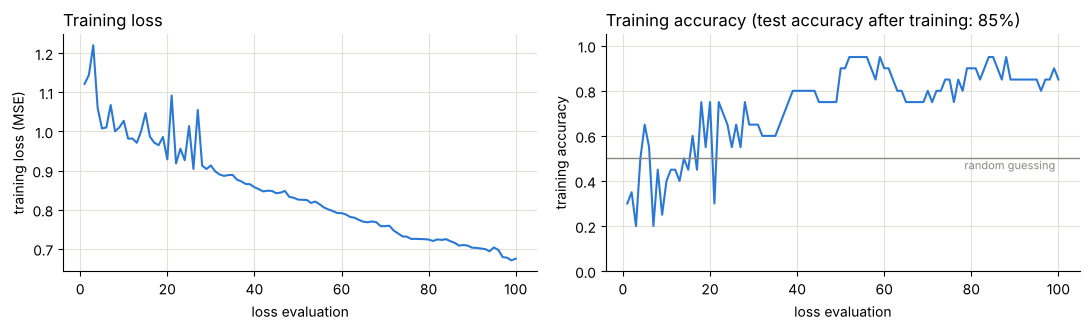

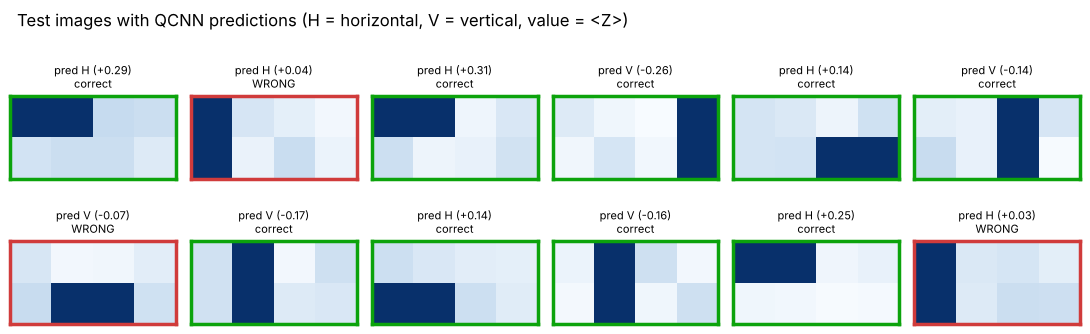

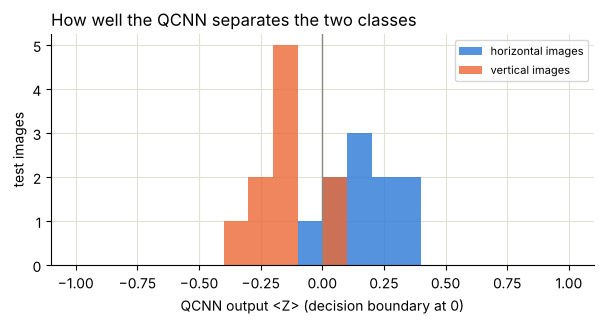

In [8]:
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(11, 3.4))
ax_loss.plot(range(1, len(history["loss"]) + 1), history["loss"], color=BLUE)
ax_loss.set_xlabel("loss evaluation"); ax_loss.set_ylabel("training loss (MSE)")
ax_loss.set_title("Training loss", loc="left")
ax_acc.plot(range(1, len(history["accuracy"]) + 1), history["accuracy"], color=BLUE)
ax_acc.axhline(0.5, color=GREY, linewidth=1)
ax_acc.text(len(history["accuracy"]), 0.5, "random guessing ", ha="right", va="top", fontsize=8, color=GREY)
ax_acc.set_ylim(0, 1.05)
ax_acc.set_xlabel("loss evaluation"); ax_acc.set_ylabel("training accuracy")
ax_acc.set_title(f"Training accuracy (test accuracy after training: {test_accuracy:.0%})", loc="left")
plt.tight_layout()
plt.show()

shown = min(TEST_IMAGES, 12)
fig, axes = plt.subplots(2, (shown + 1) // 2, figsize=(11, 3.8))
for ax, image, label, out in zip(axes.ravel(), test_x, test_y, test_outputs):
    correct = np.sign(out) == label
    ax.imshow(image.reshape(IMAGE_ROWS, IMAGE_COLS), cmap="Blues", vmin=0, vmax=1)
    ax.set_title(f"pred {'H' if out > 0 else 'V'} ({out:+.2f})\n{'correct' if correct else 'WRONG'}", fontsize=8)
    for spine in ax.spines.values():                     # coloured frame: green = correct, red = wrong
        spine.set_visible(True); spine.set_color(GOOD if correct else BAD); spine.set_linewidth(2.5)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
for ax in axes.ravel()[shown:]:
    ax.axis("off")
plt.suptitle("Test images with QCNN predictions (H = horizontal, V = vertical, value = <Z>)", x=0.02, ha="left")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 3))
bins = np.linspace(-1, 1, 21)
ax.hist(test_outputs[test_y > 0], bins=bins, color=BLUE, alpha=0.8, label="horizontal images")
ax.hist(test_outputs[test_y < 0], bins=bins, color=ORANGE, alpha=0.8, label="vertical images")
ax.axvline(0, color=GREY, linewidth=1)
ax.set_xlabel("QCNN output <Z> (decision boundary at 0)"); ax.set_ylabel("test images")
ax.set_title("How well the QCNN separates the two classes", loc="left")
ax.legend(fontsize=8)
plt.show()

---
## Section 9 - Final report

In [9]:
report = {
    "Algorithm": "QCNN classifier (horizontal vs vertical lines)",
    "CUDA-Q target": cudaq.get_target().name,
    "Number of qubits": N_QUBITS,
    "Image size": f"{IMAGE_ROWS} x {IMAGE_COLS}",
    "QCNN layers / parameters": f"{n_layers} / {n_parameters}",
    "Training / test images": f"{TRAIN_IMAGES} / {TEST_IMAGES}",
    "Optimizer / loss evaluations": f"{OPTIMIZER} / {len(history['loss'])}",
    "Time per circuit": f"{seconds_per_circuit * 1e3:.1f} ms",
    "Training time": f"{training_time:.1f} s",
    "Test-set evaluation time": f"{test_time:.2f} s",
    "Initial -> final training loss": f"{history['loss'][0]:.4f} -> {final_loss:.4f}",
    "Expected result": "accuracy clearly above 50 % (random guessing)",
    "Training accuracy": f"{train_accuracy:.2%}",
    "Test accuracy": f"{test_accuracy:.2%}",
}
width = max(len(key) for key in report)
print("=" * 70)
print("FINAL REPORT".center(70))
print("=" * 70)
for key, value in report.items():
    print(f"{key:<{width}} : {value}")
print("=" * 70)

                             FINAL REPORT                             
Algorithm                      : QCNN classifier (horizontal vs vertical lines)
CUDA-Q target                  : qpp-cpu
Number of qubits               : 8
Image size                     : 2 x 4
QCNN layers / parameters       : 3 / 12
Training / test images         : 20 / 20
Optimizer / loss evaluations   : COBYLA / 100
Time per circuit               : 1.7 ms
Training time                  : 3.4 s
Test-set evaluation time       : 0.03 s
Initial -> final training loss : 1.1214 -> 0.6704
Expected result                : accuracy clearly above 50 % (random guessing)
Training accuracy              : 90.00%
Test accuracy                  : 85.00%


---
### Things to try next
* `IMAGE_ROWS, IMAGE_COLS, LINE_LENGTH = 3, 5, 3` (15 qubits) or `4, 5, 3` (20 qubits) with `TARGET = "nvidia"` on a GPU;
  increase `MAX_ITERATIONS` to 200-300 because the deeper QCNN needs more optimizer steps.
* Raise `NOISE_LEVEL` to 0.5 and watch the test accuracy drop.
* Change the convolution block in `qcnn` (for example add `rz` gates) or the pairing rule in `qcnn_layout`, and compare
  the training curves.